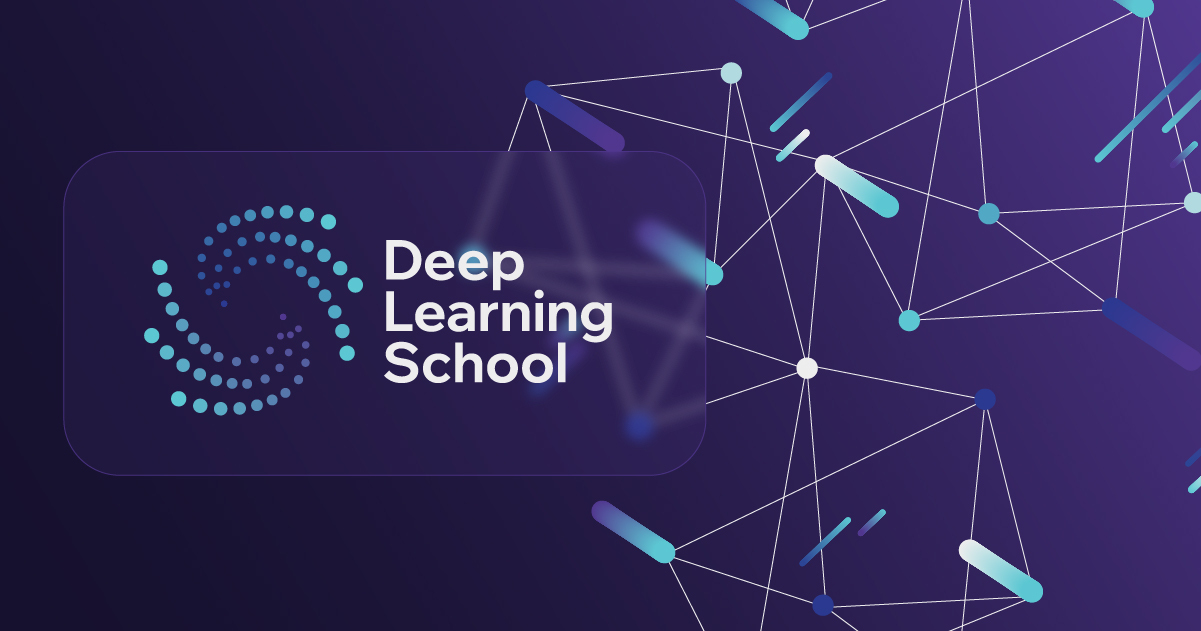

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Нейросетевая классификация текстов </b></h1>

В этом домашнем задании вам предстоит самостоятельно решить задачу классификации текстов на основе семинарского кода. Мы будем использовать датасет [ag_news](https://paperswithcode.com/dataset/ag-news). Это датасет для классификации новостей на 4 темы: "World", "Sports", "Business", "Sci/Tech".

Установим модуль datasets, чтобы нам проще было работать с данными.

In [13]:
!pip install datasets

Импорт необходимых библиотек

In [14]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import datasets

import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from datasets import load_dataset
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
import nltk

from collections import Counter
from functools import partial
from typing import List
import random
import string

import seaborn
seaborn.set(palette='summer')

In [15]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [16]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## Подготовка данных
Для вашего удобства, мы привели код обработки датасета в ноутбуке. Ваша задача --- обучить модель, которая получит максимальное возможное качество на тестовой части.

In [17]:
# Загрузим датасет
dataset = datasets.load_dataset('fancyzhx/ag_news')

Как и в семинаре, выполним следующие шаги:
* Составим словарь
* Создадим класс WordDataset
* Выделим обучающую и тестовую часть, создадим DataLoader-ы.

Дополнение: из `train` отдельно выделим **валидационную** часть (5000 примеров). По ней мы будем выбирать лучшую эпоху, а тестовую часть (`eval_dataloader`) используем только для итоговой оценки — так выбор модели не «подглядывает» в тест.

In [18]:
words = Counter()

for example in tqdm(dataset['train']['text']):
    prccessed_text = example.lower().translate(
        str.maketrans('', '', string.punctuation))

    for word in word_tokenize(prccessed_text):
        words[word] += 1


SPECIAL_TOKENS = ['<unk>', '<bos>', '<eos>', '<pad>']


def build_vocab(counter_threshold):
    kept = sorted(w for w, cnt in words.items() if cnt > counter_threshold and w not in SPECIAL_TOKENS)
    return {w: i for i, w in enumerate(SPECIAL_TOKENS + kept)}


counter_threshold = 25
word2ind = build_vocab(counter_threshold)
ind2word = {i: w for w, i in word2ind.items()}
vocab = set(word2ind)

print(f'Размер словаря: {len(vocab)}')

  0%|          | 0/120000 [00:00<?, ?it/s]

Размер словаря: 11842


In [19]:
class WordDataset:
    def __init__(self, sentences, w2i=None):
        self.data = sentences
        self.w2i = word2ind if w2i is None else w2i
        self.unk_id = self.w2i['<unk>']
        self.bos_id = self.w2i['<bos>']
        self.eos_id = self.w2i['<eos>']
        self.pad_id = self.w2i['<pad>']

    def __getitem__(self, idx: int) -> List[int]:
        processed_text = self.data[idx]['text'].lower().translate(str.maketrans('', '', string.punctuation))
        tokenized_sentence = [self.bos_id]
        tokenized_sentence += [self.w2i.get(word, self.unk_id) for word in word_tokenize(processed_text)]
        tokenized_sentence += [self.eos_id]

        train_sample = {
            "text": tokenized_sentence,
            "label": self.data[idx]['label']
        }

        return train_sample

    def __len__(self) -> int:
        return len(self.data)


def collate_fn_with_padding(
    input_batch: List[List[int]], pad_id=word2ind['<pad>'], max_len=256) -> torch.Tensor:
    seq_lens = [len(x['text']) for x in input_batch]
    max_seq_len = min(max(seq_lens), max_len)

    new_batch = []
    for sequence in input_batch:
        sequence['text'] = sequence['text'][:max_seq_len]
        for _ in range(max_seq_len - len(sequence['text'])):
            sequence['text'].append(pad_id)

        new_batch.append(sequence['text'])

    sequences = torch.LongTensor(new_batch).to(device)
    labels = torch.LongTensor([x['label'] for x in input_batch]).to(device)

    new_batch = {
        'input_ids': sequences,
        'label': labels
    }

    return new_batch

In [20]:
split = dataset['train'].train_test_split(test_size=5000, seed=42)
train_part, val_part = split['train'], split['test']

np.random.seed(42)
idx = np.random.choice(np.arange(len(dataset['test'])), 5000)
eval_part = dataset['test'].select(idx)


def make_loaders(w2i, batch_size=32):
    collate = partial(collate_fn_with_padding, pad_id=w2i['<pad>'])
    train_dl = DataLoader(WordDataset(train_part, w2i), shuffle=True, collate_fn=collate, batch_size=batch_size)
    val_dl = DataLoader(WordDataset(val_part, w2i), shuffle=False, collate_fn=collate, batch_size=batch_size)
    eval_dl = DataLoader(WordDataset(eval_part, w2i), shuffle=False, collate_fn=collate, batch_size=batch_size)
    return train_dl, val_dl, eval_dl


train_dataloader, val_dataloader, eval_dataloader = make_loaders(word2ind)

## Постановка задачи
Ваша задача -- получить максимальное возможное accuracy на `eval_dataloader`. Ниже приведена функция, которую вам необходимо запустить для обученной модели, чтобы вычислить качество её работы.

In [21]:
def evaluate(model, eval_dataloader) -> float:
    """
    Calculate accuracy on validation dataloader.
    """

    predictions = []
    target = []
    with torch.no_grad():
        for batch in eval_dataloader:
            logits = model(batch['input_ids'])
            predictions.append(logits.argmax(dim=1))
            target.append(batch['label'])

    predictions = torch.cat(predictions)
    target = torch.cat(target)
    accuracy = (predictions == target).float().mean().item()

    return accuracy

## Ход работы
Оценка за домашнее задание складывается из четырех частей:
### Запуск базовой модели с семинара на новом датасете (1 балл)
На семинаре мы создали модель, которая дает на нашей задаче довольно высокое качество. Ваша цель --- обучить ее и вычислить `score`, который затем можно будет использовать в качестве бейзлайна.

В модели появится одно важное изменение: количество классов теперь равно не 2, а 4. Обратите на это внимание и найдите, что в коде создания модели нужно модифицировать, чтобы учесть это различие.

### Проведение экспериментов по улучшению модели (2 балла за каждый эксперимент)
Чтобы улучшить качество базовой модели, можно попробовать различные идеи экспериментов. Каждый выполненный эксперимент будет оцениваться в 2 балла. Для получения полного балла за этот пункт вам необходимо выполнить по крайней мере 2 эксперимента. Не расстраивайтесь, если какой-то эксперимент не дал вам прироста к качеству: он все равно зачтется, если выполнен корректно.

Вот несколько идей экспериментов:
* **Модель RNN**. Попробуйте другие нейросетевые модели --- LSTM и GRU. Мы советуем обратить внимание на [GRU](https://pytorch.org/docs/stable/generated/torch.nn.GRU.html), так как интерфейс этого класса ничем не отличается от обычной Vanilla RNN, которую мы использовали на семинаре.
* **Увеличение количества рекуррентных слоев модели**. Это можно сделать с помощью параметра `num_layers` в классе `nn.RNN`. В такой модели выходы первой RNN передаются в качестве входов второй RNN и так далее.
* **Изменение архитектуры после применения RNN**. В базовой модели используется агрегация со всех эмбеддингов. Возможно, вы захотите конкатенировать результат агрегации и эмбеддинг с последнего токена.
* **Подбор гиперпараметров и обучение до сходимости**. Возможно, для получения более высокого качества просто необходимо увеличить количество эпох обучения нейросети, а также попробовать различные гиперпараметры: размер словаря, `dropout_rate`, `hidden_dim`.

Обратите внимание, что главное правило проведения экспериментов --- необходимо совершать одно архитектурное изменение в одном эксперименте. Если вы совершите несколько изменений, то будет неясно, какое именно из изменений дало прирост к качеству.

### Получение высокого качества (3 балла)
В конце вашей работы вы должны указать, какая из моделей дала лучший результат, и вывести качество, которое дает лучшая модель, с помощью функции `evaluate`. Ваша модель будет оцениваться по метрике `accuracy` следующим образом:
* $accuracy < 0.9$ --- 0 баллов;
* $0.9 \leqslant accuracy < 0.91$ --- 1 балл;
* $0.91 \leqslant accuracy < 0.915$ --- 2 балла;
* $0.915 \leqslant accuracy$ --- 3 балла.

### Оформление отчета (2 балла)
В конце работы подробно опишите все проведенные эксперименты.
* Укажите, какие из экспериментов принесли улучшение, а какие --- нет.
* Проанализируйте графики сходимости моделей в проведенных экспериментах. Являются ли колебания качества обученных моделей существенными в зависимости от эпохи обучения, или же сходимость стабильная?
* Укажите, какая модель получилась оптимальной.

Желаем удачи!

In [22]:
class CharLM(nn.Module):
    def __init__(
        self,
        hidden_dim: int,
        vocab_size: int,
        num_classes: int = 4,
        aggregation_type: str = 'max',
        rnn_type: str = 'RNN',
        dropout: float = 0.1,
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        rnn_cls = {'RNN': nn.RNN, 'GRU': nn.GRU}[rnn_type]
        self.rnn = rnn_cls(hidden_dim, hidden_dim, batch_first=True)

        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=dropout)
        self.aggregation_type = aggregation_type

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1)
        else:
            raise ValueError("Invalid aggregation_type")

        output = self.dropout(self.linear(self.non_lin(output)))
        prediction = self.projection(self.non_lin(output))
        return prediction

## Обучение
Функция `train_model` оценивает модель на **валидации** дважды за эпоху и в конце возвращает веса той точки, где val accuracy максимальна. Все модели обучаются с одинаковыми настройками (Adam, lr=1e-3, batch 32, 5 эпох, seed 42).

In [23]:
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def train_model(model, train_dl, val_dl, n_epochs=5, lr=1e-3, name='model'):
    """
    Обучает модель и возвращает веса точки с максимальной accuracy на ВАЛИДАЦИИ.
    Возвращает: модель (в eval-режиме), историю val accuracy (2 значения за эпоху),
    список значений train loss по шагам.
    """
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    n_batches = len(train_dl)
    eval_points = {n_batches // 2, n_batches}  # после каких батчей (с единицы) оцениваем

    history, losses = [], []
    best_acc, best_state = -1.0, None

    for epoch in range(n_epochs):
        model.train()
        pbar = tqdm(train_dl, desc=f'[{name}] epoch {epoch + 1}')

        for i, batch in enumerate(pbar):
            optimizer.zero_grad()
            loss = criterion(model(batch['input_ids']), batch['label'])
            loss.backward()
            optimizer.step()
            losses.append(loss.item())

            if (i + 1) in eval_points:
                model.eval()
                acc = evaluate(model, val_dl)
                model.train()
                history.append(acc)
                if acc > best_acc:
                    best_acc = acc
                    best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
                pbar.set_description(
                    f'[{name}] epoch {epoch + 1}, loss={loss.item():.3f}, val acc={acc:.4f}')

        print(f'[{name}] конец эпохи {epoch + 1}: val accuracy = {history[-1]:.4f}')

    model.load_state_dict(best_state)
    model.eval()
    print(f'[{name}] лучшая val accuracy = {best_acc:.4f} (загружены веса этой точки)')
    return model, history, losses


def plot_history(history, losses, name, window=200):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    epochs = np.arange(1, len(history) + 1) / 2  # две оценки за эпоху
    axes[0].plot(epochs, history, marker='o')
    axes[0].set_title(f'Val accuracy: {name}')
    axes[0].set_xlabel('эпоха')
    axes[0].set_ylabel('accuracy (val)')
    axes[0].grid(True)

    smooth = np.convolve(losses, np.ones(window) / window, mode='valid')
    axes[1].plot(smooth)
    axes[1].set_title(f'Train loss (скользящее среднее, окно {window}): {name}')
    axes[1].set_xlabel('шаг обучения')
    axes[1].set_ylabel('loss')
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

## Базовая модель (1 балл)
Модель с семинара: однослойная RNN, max-агрегация по всем выходам, hidden_dim=256. Единственное отличие от семинара — `num_classes=4` (4 темы вместо 2 классов).

[baseline RNN] epoch 1:   0%|          | 0/3594 [00:00<?, ?it/s]

[baseline RNN] конец эпохи 1: val accuracy = 0.8934


[baseline RNN] epoch 2:   0%|          | 0/3594 [00:00<?, ?it/s]

[baseline RNN] конец эпохи 2: val accuracy = 0.8968


[baseline RNN] epoch 3:   0%|          | 0/3594 [00:00<?, ?it/s]

[baseline RNN] конец эпохи 3: val accuracy = 0.9076


[baseline RNN] epoch 4:   0%|          | 0/3594 [00:00<?, ?it/s]

[baseline RNN] конец эпохи 4: val accuracy = 0.9022


[baseline RNN] epoch 5:   0%|          | 0/3594 [00:00<?, ?it/s]

[baseline RNN] конец эпохи 5: val accuracy = 0.9124
[baseline RNN] лучшая val accuracy = 0.9124 (загружены веса этой точки)


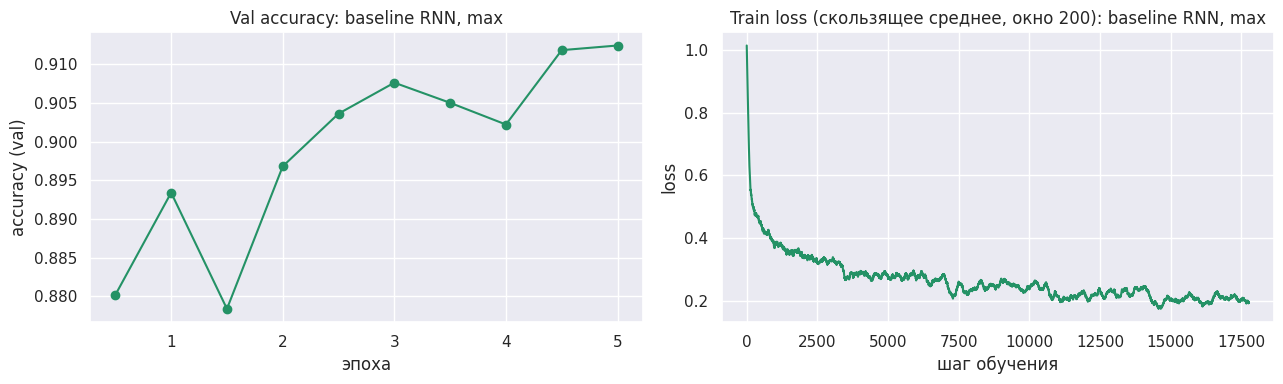

Baseline: val = 0.9124, test (eval) = 0.8996


In [24]:
set_seed(42)
baseline = CharLM(hidden_dim=256, vocab_size=len(word2ind), num_classes=4, aggregation_type='max', rnn_type='RNN')
baseline, hist_baseline, loss_baseline = train_model(baseline, train_dataloader, val_dataloader, n_epochs=5, name='baseline RNN')
plot_history(hist_baseline, loss_baseline, 'baseline RNN, max')

test_acc_baseline = evaluate(baseline, eval_dataloader)
print(f'Baseline: val = {max(hist_baseline):.4f}, test (eval) = {test_acc_baseline:.4f}')

## Эксперимент 1: GRU вместо RNN (2 балла)
Меняем только тип рекуррентного слоя: `nn.RNN` → `nn.GRU`. Всё остальное — как в baseline (hidden_dim, агрегация, словарь, оптимизатор, число эпох).

[GRU] epoch 1:   0%|          | 0/3594 [00:00<?, ?it/s]

[GRU] конец эпохи 1: val accuracy = 0.9066


[GRU] epoch 2:   0%|          | 0/3594 [00:00<?, ?it/s]

[GRU] конец эпохи 2: val accuracy = 0.9086


[GRU] epoch 3:   0%|          | 0/3594 [00:00<?, ?it/s]

[GRU] конец эпохи 3: val accuracy = 0.9108


[GRU] epoch 4:   0%|          | 0/3594 [00:00<?, ?it/s]

[GRU] конец эпохи 4: val accuracy = 0.9150


[GRU] epoch 5:   0%|          | 0/3594 [00:00<?, ?it/s]

[GRU] конец эпохи 5: val accuracy = 0.9128
[GRU] лучшая val accuracy = 0.9150 (загружены веса этой точки)


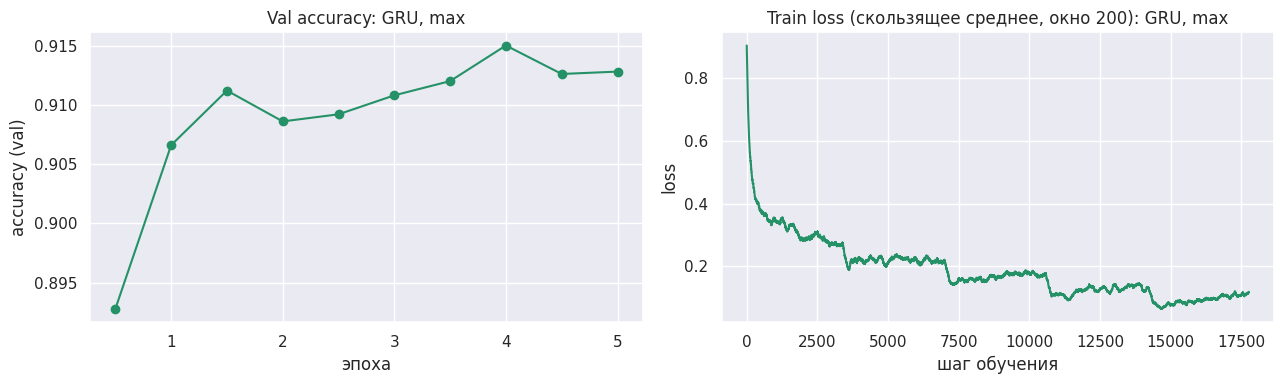

GRU: val = 0.9150, test (eval) = 0.9048


In [25]:
set_seed(42)
gru_model = CharLM(hidden_dim=256, vocab_size=len(word2ind), num_classes=4, aggregation_type='max', rnn_type='GRU')
gru_model, hist_gru, loss_gru = train_model(gru_model, train_dataloader, val_dataloader, n_epochs=5, name='GRU')
plot_history(hist_gru, loss_gru, 'GRU, max')

test_acc_gru = evaluate(gru_model, eval_dataloader)
print(f'GRU: val = {max(hist_gru):.4f}, test (eval) = {test_acc_gru:.4f}')

## Эксперимент 2: больший словарь (2 балла)
К модели из эксперимента 1 (GRU) добавляем одно изменение — порог частоты слова в словаре снижаем с 25 до 5. Меньше слов превращается в `<unk>`, но растёт размер эмбеддинг-матрицы. Датасеты и DataLoader-ы пересобираем под новый словарь (`make_loaders`).

Размер словаря: 11842 -> 27694


[GRU, словарь >5] epoch 1:   0%|          | 0/3594 [00:00<?, ?it/s]

[GRU, словарь >5] конец эпохи 1: val accuracy = 0.9038


[GRU, словарь >5] epoch 2:   0%|          | 0/3594 [00:00<?, ?it/s]

[GRU, словарь >5] конец эпохи 2: val accuracy = 0.9190


[GRU, словарь >5] epoch 3:   0%|          | 0/3594 [00:00<?, ?it/s]

[GRU, словарь >5] конец эпохи 3: val accuracy = 0.9194


[GRU, словарь >5] epoch 4:   0%|          | 0/3594 [00:00<?, ?it/s]

[GRU, словарь >5] конец эпохи 4: val accuracy = 0.9158


[GRU, словарь >5] epoch 5:   0%|          | 0/3594 [00:00<?, ?it/s]

[GRU, словарь >5] конец эпохи 5: val accuracy = 0.9106
[GRU, словарь >5] лучшая val accuracy = 0.9194 (загружены веса этой точки)


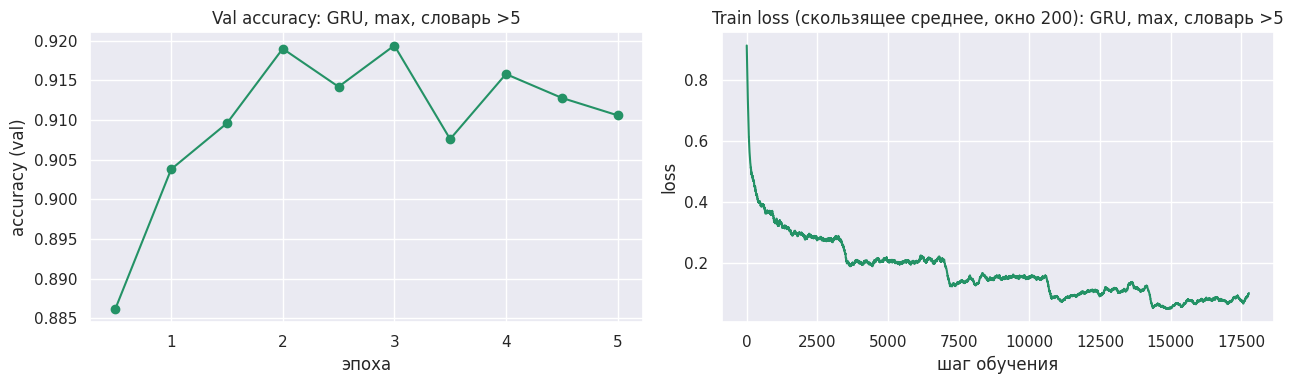

GRU, словарь >5: val = 0.9194, test (eval) = 0.9120


In [26]:
word2ind_big = build_vocab(counter_threshold=5)
print(f'Размер словаря: {len(word2ind)} -> {len(word2ind_big)}')
train_dl_big, val_dl_big, eval_dl_big = make_loaders(word2ind_big)

set_seed(42)
vocab_model = CharLM(hidden_dim=256, vocab_size=len(word2ind_big), num_classes=4, aggregation_type='max', rnn_type='GRU')
vocab_model, hist_vocab, loss_vocab = train_model(vocab_model, train_dl_big, val_dl_big, n_epochs=5, name='GRU, словарь >5')
plot_history(hist_vocab, loss_vocab, 'GRU, max, словарь >5')

test_acc_vocab = evaluate(vocab_model, eval_dl_big)  # именно eval_dl_big: у модели другой словарь
print(f'GRU, словарь >5: val = {max(hist_vocab):.4f}, test (eval) = {test_acc_vocab:.4f}')

## Итог: лучшая модель (3 балла)
Лучшую модель выбираем по **валидации**, а её качество считаем функцией `evaluate` на тестовой части.

In [27]:
candidates = {
    'baseline RNN, max':             (baseline,    eval_dataloader, hist_baseline),
    'Эксп. 1: GRU, max':             (gru_model,   eval_dataloader, hist_gru),
    'Эксп. 2: GRU, max, словарь >5': (vocab_model, eval_dl_big,     hist_vocab),
}

print(f'{"модель":32s} {"val (лучшая)":>13s} {"test (eval)":>12s}')
for name, (m, dl, hist) in candidates.items():
    m.eval()
    print(f'{name:32s} {max(hist):13.4f} {evaluate(m, dl):12.4f}')

best_name = max(candidates, key=lambda n: max(candidates[n][2]))  # выбор по val
best_model, best_dl, _ = candidates[best_name]
best_model.eval()
final_accuracy = evaluate(best_model, best_dl)

print(f'\nЛучшая модель: {best_name}')
print(f'Accuracy на eval_dataloader: {final_accuracy:.4f}')

модель                            val (лучшая)  test (eval)
baseline RNN, max                       0.9124       0.8996
Эксп. 1: GRU, max                       0.9150       0.9048
Эксп. 2: GRU, max, словарь >5           0.9194       0.9120

Лучшая модель: Эксп. 2: GRU, max, словарь >5
Accuracy на eval_dataloader: 0.9120


### Отчёт

В работе была реализована базовая модель RNN для классификации новостей на 4 категории, а также проведены два эксперимента по улучшению качества.

В первом эксперименте RNN была заменена на GRU. Accuracy на тестовой выборке увеличилась с **0.8996 до 0.9048**, что показывает положительное влияние изменения архитектуры.

Во втором эксперименте был увеличен словарь: порог частоты слов снижен с 25 до 5. Его размер вырос с 11842 до 27694 слов. Accuracy достигла **0.9120**.

По графикам обучения видно, что качество моделей в целом растёт, однако после достижения максимума наблюдаются небольшие колебания. Наилучший результат показала GRU с увеличенным словарём.

**Вывод:** оба эксперимента улучшили качество базовой модели. Лучшая модель — GRU с порогом словаря 5, её итоговая accuracy на тестовой выборке составляет **0.9120**.